### Práctica 2: Localización de un robot con diferentes sensores

En esta práctica vamos a trabajar en un problema muy común en la robótica: la localización de un robot móvil empleando la información de sus sensores.

Los robots móviles pueden disponer de varias fuentes de información para localizarse en su entorno:

- **Receptores GNSS** (Global Navigation Satellite System, Sistema Global de Navegación por Satélite): reciben señales de constelaciones de satélites (GPS, Galileo o GLONASS) y las utilizan para triangular su posición sobre el globo terrestre (latitud, longitud y altitud). Es el sistema más utilizado para la localización de robots en escenarios exteriores, pero no suele estar disponible en interiores. Además, en escenarios con una densidad considerable de obstáculos (por ejemplo, un valle entre montañas o una ciudad con edificios altos), se puede ver afectado por la falta de cobertura o por señales rebotadas. En la práctica, esto se traduce en medidas ruidosas y, ocasionalmente, outliers (medidas erróneas).

- **IMU** (Inertial Measurement Unit, Unidad de Medida Inercial): combina acelerómetros, giroscopios y magnetómetros para determinar la aceleración, velocidad angular y orientación del robot. La integración de estas medidas permite obtener la posición y orientación. Sin embargo, estos sistemas presentan tanto ruidos como derivas, y la integración de estos errores los hace crecer con el tiempo. En la práctica, esto se traduce en sesgos que se acumulan y hacen que la posición estimada se desvíe progresivamente de la real.

- **Odometría**: permite estimar la posición del robot a partir de las medidas de sus encoders, unos sensores que miden el desplazamiento y velocidad de sus ruedas. Fenómenos como el deslizamiento de las ruedas pueden dar lugar a derivas que separen progresivamente la posición estimada de la real. En la práctica, esto se traduce en errores de escala y ruido que también se acumulan.

Todas estas fuentes tienen sus fortalezas y debilidades:

| Sensor | Frecuencia | Precisión a corto plazo | Precisión a largo plazo | Disponibilidad |
|--------|------------|-------------------------|-------------------------|----------------|
| GNSS | Baja (1-10 Hz) | Media	| Alta | Solo exterior |
| IMU | Alta (100-200 Hz) | Alta | Baja (deriva) | Cualquiera |
| Encoders | Alta (50-100 Hz) | Alta | Baja (deriva) | Cualquiera |

Por ello, se suelen combinar para una localización más precisa e incluso reforzar con técnicas de localización en mapas. Este es el caso del algoritmo SLAM (Simultaneous Location And Mapping), que localiza al robot en un mapa conocido a partir de la información de sus sensores sobre su entorno (escáneres láser, cámaras RGBD, sensores ultrasónicos e infrarrojos...). 

El objetivo de esta práctica es fusionar las tres fuentes para obtener una estimación de la posición del robot que sea mejor que cualquiera de ellas por separado. Para ello, vamos a trabajar con datos reales de trayectorias de un robot móvil, simular las medidas de cada sensor con sus errores característicos, e implementar dos técnicas de fusión: el filtro de Kalman y el filtro de partículas.

#### Organización de los archivos:

Los archivos de la práctica se organizan de la siguiente manera:

- *practice.ipynb*: 
    - TODO: Aquí tienes que implementar los filtros y analizar su rendimiento. 
- *path_generator.ipynb*: 
    - Genera varias rutas reales del robot para probar los filtros desarrollados.
    - TODO: Aquí puedes generar tus propias rutas.
- *src/sensor_simulator.py*: 
    - Simula las medidas de los sensores a partir de las rutas reales del robot.
    - Funciones relevantes: 
        - *sim_sensors(df_gt)*: Genera las medidas de los sensores.
- src/utils.py: 
    - Contiene métodos para mostrar gráficamente los resultados de los filtros.
    - Funciones relevantes: 
        - *load_path(name)*: Carga una ruta a partir de un archivo CSV.
        - *plot_path(gt, estimates)*: Dibuja las rutas real y estimada.
        - *plot_error(gt, estimates)*: Dibuja el error de la ruta estimada frente a la real.
- src/metrics.py:
    - Contiene métodos para calcular los errores de estimación de los filtros.
    - Funciones relevantes:
        - *summary_metrics(estimate, ground_truth)*: Calcula errores RMSE, ATE y RPE.

#### Entrega de la práctica:
Entrega: Carpeta comprimida con nombre Apellido1_Apellido2_Nombre.zip

Fecha: 24/11/2026 - 23:59

Contacto: juan.roldan@uam.es

In [9]:
import numpy as np
import sys
sys.path.append('src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from utils import load_path, plot_path, plot_error
from sensor_simulator import SensorSimulator
from metrics import summary_metrics, rmse_posicion

### Ejercicio 1: Filtro de Kalman para GPS

Vamos a comenzar con un modelo sencillo de velocidad constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,    v_{x},  v_{y}]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v_{x} \\
\dot{y} &= v_{y} \\
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_{xk} \Delta t \\
y_{k+1} &= y_k + v_{yk} \Delta t \\
\end{aligned}
$$

A) Implementa un filtro de Kalman que trabaje con las medidas del GPS y un modelo de velocidad constante.

1. Crea la función de predicción, que propaga el estado y la covarianza utilizando un modelo de movimiento.
2. Crea la función de actualización, que corrige el estado empleando la medida del GPS.

In [10]:
class KalmanFilterGPS:
    """
    Filtro de Kalman para GPS
    Estado: [x, y, vx, vy]
    Predicción con modelo de velocidad constante
    Actualización con medidas del GPS
    """
    def __init__(self, dt, sigma_gps=1.5):
        self.dt = dt
        self.sigma_gps = sigma_gps
        
        # Estado inicial
        self.x = np.zeros(4)  # [x, y, vx, vy]
        
        # Covarianza inicial
        self.P = np.eye(4) * 10.0
        
        # Matriz de transición
        # x_{k+1}  = x_k + vx·dt      -> fila [1, 0, dt, 0]
        # y_{k+1}  = y_k + vy·dt      -> fila [0, 1, 0, dt]
        # vx_{k+1} = vx_k             -> fila [0, 0, 1, 0]
        # vy_{k+1} = vy_k             -> fila [0, 0, 0, 1]
        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])
        
        # Ruido del proceso
        q = 0.1
        self.Q = q * np.array([
            [dt**3/3, 0, dt**2/2, 0],
            [0, dt**3/3, 0, dt**2/2],
            [dt**2/2, 0, dt, 0],
            [0, dt**2/2, 0, dt]
        ])
        
        # Matriz de medida
        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])
        
        # Ruido de medida
        self.R = np.eye(2) * sigma_gps**2
    
    def predict(self):
        """Paso de predicción"""
        self.x = self.F @ self.x 
        self.P = self.F @ self.P @ np.transpose(self.F) + self.Q
            
    def update(self, z):
        """Paso de actualización"""
        z = np.asarray(z)

        # Innovación
        y = z - self.H @ self.x

        # Covarianza de la innovación
        S = self.H @ self.P @ np.transpose(self.H) + self.R

        # Ganancia de Kalman
        K = self.P @ np.transpose(self.H) @ np.linalg.inv(S)

        # Actualización del estado
        self.x = self.x + K @ y

        # Actualización de la covarianza
        I = np.eye(self.P.shape[0])
        self.P = (I - K @ self.H) @ self.P
    
    def step(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update(z_gps)
        return self.x.copy()

B) Compara el error de las medidas brutas del GPS con el del filtro de Kalman. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


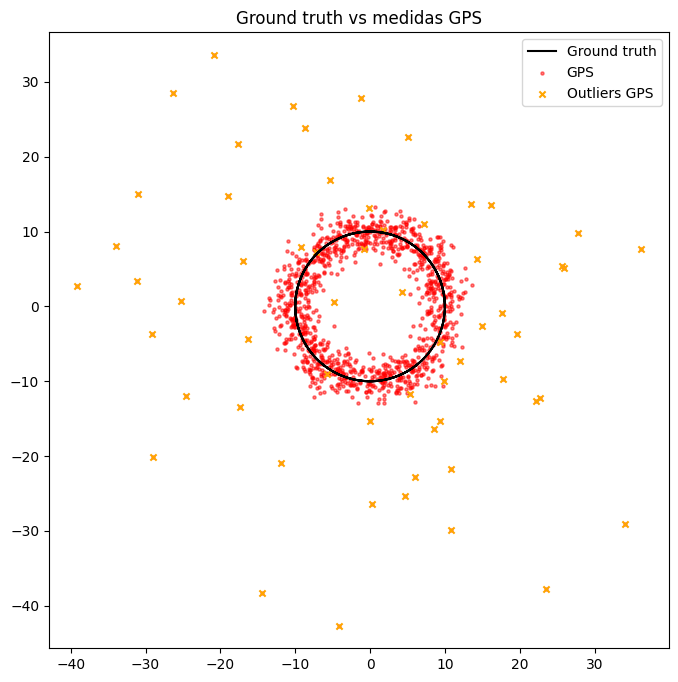

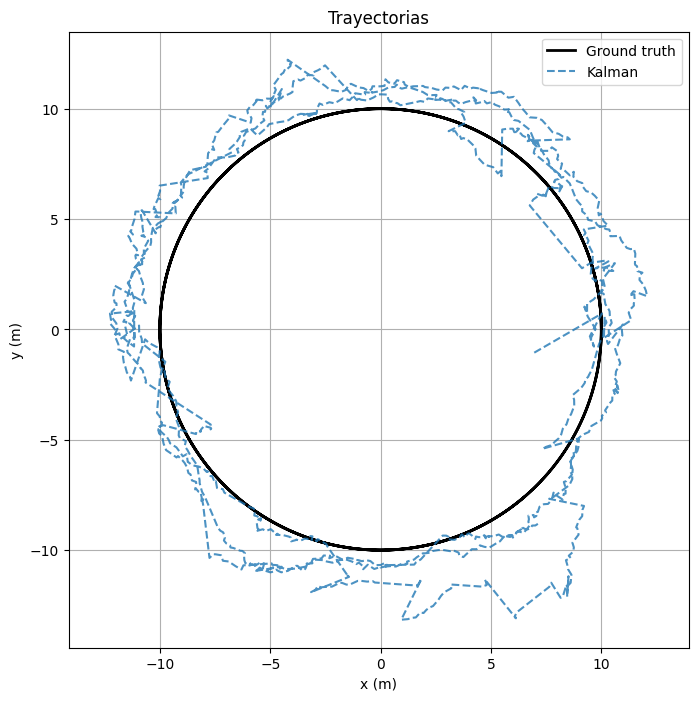

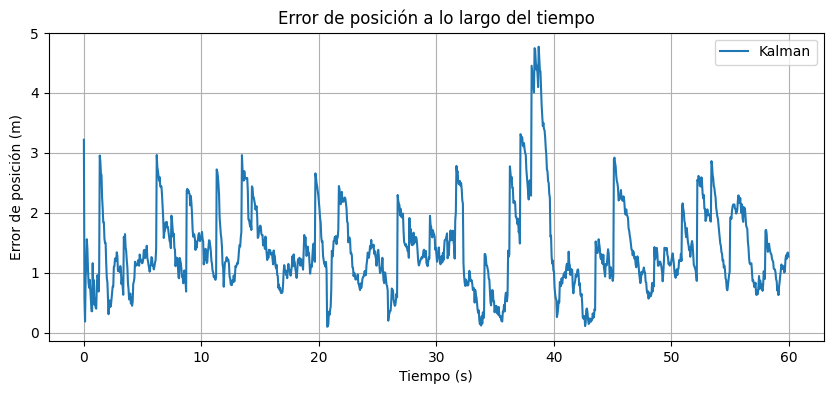

Kalman       RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m


In [11]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPS(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza el desempeño del filtro de Kalman. ¿El filtro mejora la señal del GPS? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría reducir?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Comparamos el error del GPS sin filtrar con el del filtro, miramos cuánto influyen los outliers y probamos otros valores de $q$.

GPS sin filtrar  RMSE=5.232 m  ATE=5.231 m  RPE=4.082 m
Kalman           RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m

Error máximo: GPS = 51.20 m, Kalman = 4.77 m
Error medio del Kalman: 1.40 m

Outliers: 59 de 1200 medidas
RMSE del GPS sin outliers: 2.14 m

Radio real: 9.98 m, radio estimado: 11.01 m

RMSE según q:
  q = 0.01: RMSE = 3.002 m
  q = 0.1: RMSE = 1.582 m
  q = 1: RMSE = 1.606 m
  q = 10: RMSE = 2.038 m


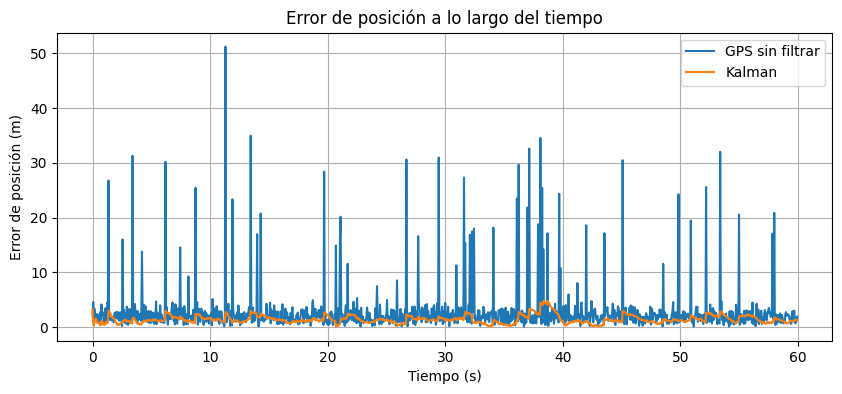

In [12]:
# GPS sin filtrar vs filtro de Kalman

z_gps = medidas['gps'][['x_gps', 'y_gps']].values        # medidas del GPS
es_outlier = medidas['gps']['is_outlier'].values == 1     # True si la medida es un outlier

# 1. Errores del GPS y del filtro
for nombre, est in {'GPS sin filtrar': z_gps, 'Kalman': estimates_kf}.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:16s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

# 2. Error máximo y error medio
error_gps = np.linalg.norm(z_gps - gt_array[:, :2], axis=1)
error_kf = np.linalg.norm(estimates_kf[:, :2] - gt_array[:, :2], axis=1)
print(f"\nError máximo: GPS = {error_gps.max():.2f} m, Kalman = {error_kf.max():.2f} m")
print(f"Error medio del Kalman: {error_kf.mean():.2f} m")

# 3. RMSE del GPS si quitamos los outliers
print(f"\nOutliers: {es_outlier.sum()} de {len(es_outlier)} medidas")
print(f"RMSE del GPS sin outliers: {rmse_posicion(z_gps[~es_outlier], gt_array[~es_outlier]):.2f} m")

# 4. Radio del círculo real y del estimado (en la gráfica el estimado se ve más grande)
centro = gt_array[:, :2].mean(axis=0)
radio_real = np.linalg.norm(gt_array[:, :2] - centro, axis=1).mean()
radio_kf = np.linalg.norm(estimates_kf[:, :2] - centro, axis=1).mean()
print(f"\nRadio real: {radio_real:.2f} m, radio estimado: {radio_kf:.2f} m")

# 5. Probamos otros valores de q (en la clase q = 0.1)
print("\nRMSE según q:")
for q in [0.01, 0.1, 1, 10]:
    kf_q = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
    kf_q.Q = kf_q.Q / 0.1 * q
    est_q = np.array([kf_q.step(z) for z in z_gps])
    print(f"  q = {q}: RMSE = {rmse_posicion(est_q, gt_array):.3f} m")

# 6. Error a lo largo del tiempo
plot_error(df_gt, {'GPS sin filtrar': z_gps, 'Kalman': estimates_kf})

#### Respuestas

**¿El filtro mejora la señal del GPS?**

Sí. En la gráfica del error se ve claramente: el GPS tiene muchos picos (los outliers) y el filtro se queda casi todo el rato por debajo de 2-3 m. El RMSE baja de 5.23 m a 1.58 m, un 70 % menos, y el error máximo pasa de 51 m a 4.8 m.

El RPE también baja, de 4.08 m a 0.91 m, es decir, la trayectoria del filtro no da saltos de una muestra a la siguiente como pasa con el GPS.

Si quitamos los outliers del GPS la mejora ya no es tan grande: el GPS sin outliers tiene un RMSE de 2.14 m y el filtro de 1.58 m. Mejora, pero esperábamos más teniendo 20 medidas por segundo.

**¿El error es adecuado o excesivo para la tarea?**

Creemos que es excesivo. El error medio es de 1.4 m y hay momentos de casi 5 m, en un círculo de unos 10 m de radio. Para saber más o menos por dónde va el robot podría valer, pero para seguir una ruta o pasar cerca de obstáculos no.

**¿Qué causas puede tener este error?**

- **El modelo de velocidad constante.** En la gráfica de la trayectoria vimos que el círculo estimado queda por fuera del real (radio de 11.0 m frente a 9.98 m). Pensamos que es porque el modelo predice que el robot sigue recto y en realidad está girando todo el tiempo, así que en cada predicción se va hacia fuera y el GPS solo lo corrige en parte. Además el RMSE y el ATE salen casi iguales, lo que nos indica que el error no es que toda la trayectoria esté desplazada, sino que tiene otra forma.
- **Los outliers.** El filtro no sabe que son medidas malas y las usa igual, por eso en la gráfica el error del filtro también sube un poco en los instantes en los que el GPS tiene un pico.
- **El valor de $q$.** Probando valores vimos que con $q$ pequeño el error sube mucho (3.0 m con $q = 0.01$), porque el filtro se fía demasiado de que el robot va recto, y con $q$ grande también sube (2.04 m con $q = 10$), porque se fía demasiado de cada medida, outliers incluidos. El $q = 0.1$ que viene en la clase es el mejor de los que hemos probado.

**¿Cómo se podría reducir?**

- Descartar los outliers antes de usarlos en el filtro (es lo que se hace en el apartado C).
- Usar un modelo que tenga en cuenta los giros, o añadir sensores que midan el movimiento, como la IMU y los encoders (ejercicio 2).

C) Implementa una nueva función de actualización que no pase los outliers al filtro.

In [13]:
class KalmanFilterGPSwithGating(KalmanFilterGPS):

    def update_gating(self, z, threshold=3.0):
        """Solo actualiza si la innovación es razonable."""
        z = np.asarray(z)

        # Innovación
        y = z - self.H @ self.x

        # Covarianza de la innovación
        S = self.H @ self.P @ self.H.T + self.R

        # Distancia de Mahalanobis
        d = np.sqrt(y @ np.linalg.inv(S) @ y)

        if d < threshold:
            self.update(z)

    def step_gating(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update_gating(z_gps)
        return self.x.copy()

D) Compara el error del filtro de Kalman antes y después del gating. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


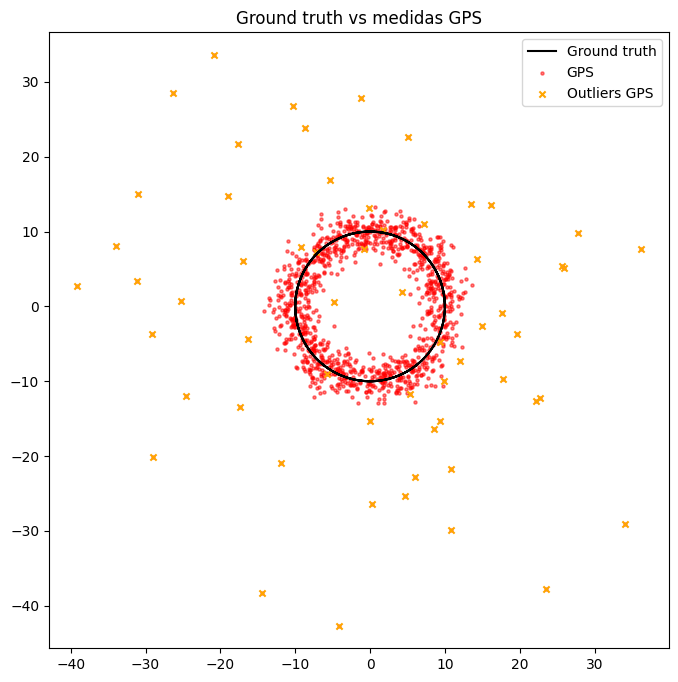

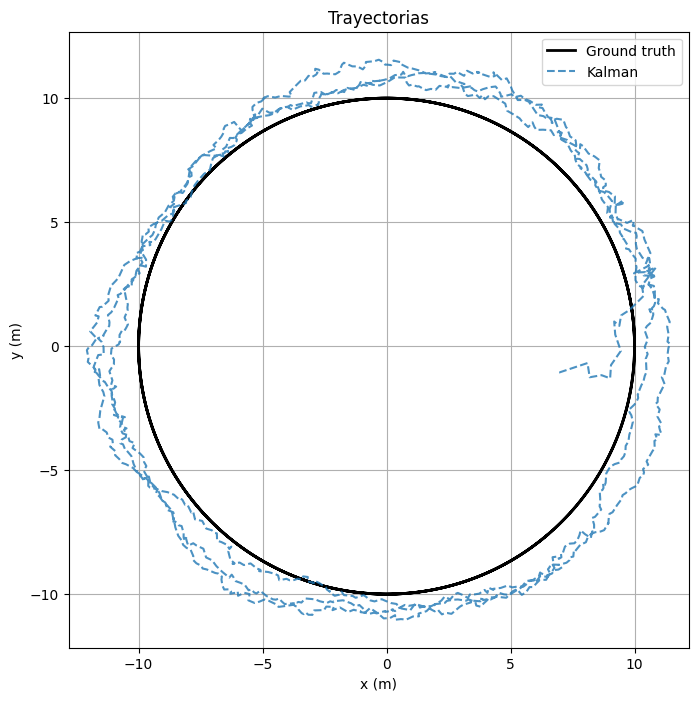

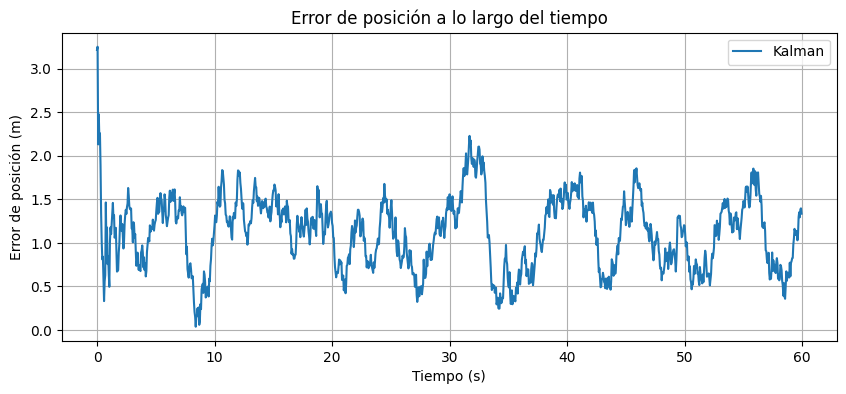

Kalman       RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m


In [14]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step_gating(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al filtrar los outliers? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Ejecutamos los dos filtros con las mismas medidas y miramos qué medidas rechaza el gating.

Kalman sin gating  RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m
Kalman con gating  RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m

Outliers rechazados: 56 de 59
Medidas buenas rechazadas: 28

Radio real: 9.98 m, radio estimado con gating: 10.86 m
Kalman con gating y q = 1: RMSE = 0.820 m


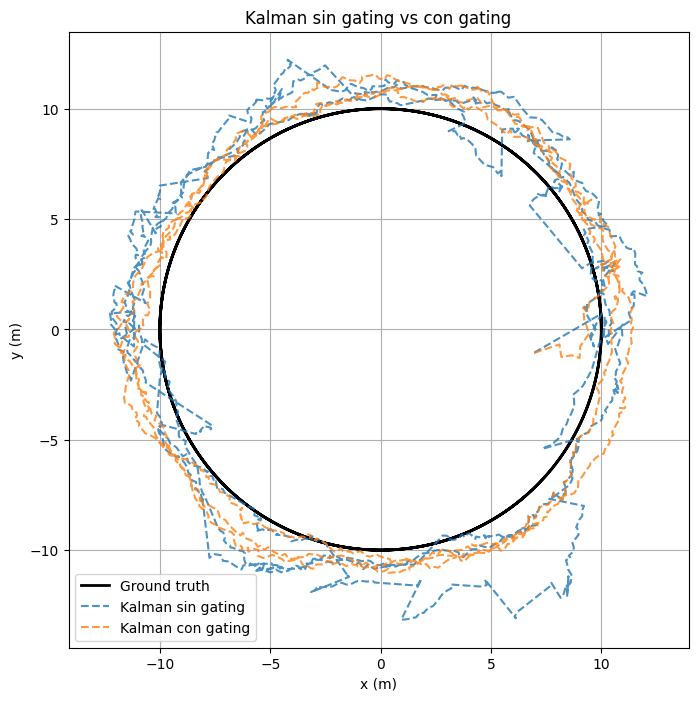

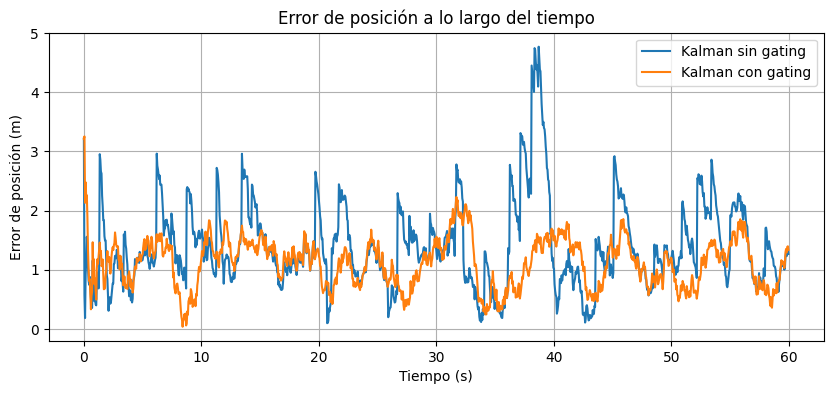

In [15]:
# Kalman sin gating vs con gating 
# z_gps, es_outlier, centro y radio_real vienen de la celda de análisis del apartado B

# 1. Ejecutamos los dos filtros con las mismas medidas
kf_sin = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
est_sin = np.array([kf_sin.step(z) for z in z_gps])

kf_con = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
est_con = []
rechazada = []
for z in z_gps:
    kf_con.predict()
    x_antes = kf_con.x.copy()
    kf_con.update_gating(z)
    rechazada.append(np.array_equal(kf_con.x, x_antes))   # si el estado no ha cambiado, la medida se ha rechazado
    est_con.append(kf_con.x.copy())
est_con = np.array(est_con)
rechazada = np.array(rechazada)

# 2. Errores
estimaciones = {'Kalman sin gating': est_sin, 'Kalman con gating': est_con}
for nombre, est in estimaciones.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:18s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

# 3. Medidas rechazadas
print(f"\nOutliers rechazados: {(rechazada & es_outlier).sum()} de {es_outlier.sum()}")
print(f"Medidas buenas rechazadas: {(rechazada & ~es_outlier).sum()}")

# 4. Radio del círculo estimado con gating
radio_con = np.linalg.norm(est_con[:, :2] - centro, axis=1).mean()
print(f"\nRadio real: {radio_real:.2f} m, radio estimado con gating: {radio_con:.2f} m")

# 5. Con gating probamos a subir q de 0.1 a 1
kf_q = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
kf_q.Q = kf_q.Q * 10
est_q = np.array([kf_q.step_gating(z) for z in z_gps])
print(f"Kalman con gating y q = 1: RMSE = {rmse_posicion(est_q, gt_array):.3f} m")

# 6. Gráficas
plot_path(df_gt, estimaciones, title='Kalman sin gating vs con gating')
plot_error(df_gt, estimaciones)

#### Respuestas

**¿Cuánto ha decrecido el error al filtrar los outliers?**

El RMSE baja de 1.58 m a 1.19 m (un 25 % menos) y el RPE de 0.91 m a 0.43 m. En la gráfica del error se ve que desaparecen los picos que tenía el filtro sin gating cuando llegaba un outlier, y la trayectoria queda más suave.

El gating rechaza 56 de los 59 outliers. También rechaza 28 medidas que eran buenas, pero con 1200 medidas en total no parece que eso afecte mucho.

**¿El error es adecuado o excesivo para la tarea?**

Ha mejorado, pero sigue siendo algo alto por lo mismo que en el apartado B: vale para saber por dónde va el robot, pero no para moverse con precisión.

**¿Qué causas puede tener este error?**

Ahora que casi no entran outliers, lo que queda es sobre todo el problema del modelo de velocidad constante en la curva. El círculo estimado sigue saliendo más grande que el real (10.86 m de radio frente a 9.98 m) y el gating no puede arreglarlo, porque no tiene nada que ver con los outliers. Además está el ruido normal del GPS ($\sigma$ = 1.5 m) y los 3 outliers que pasan el gating.

**¿Cómo se podría seguir reduciendo?**

En el apartado B vimos que subir $q$ empeoraba el resultado porque el filtro se fiaba más de los outliers. Como ahora el gating los quita, probamos con $q = 1$ y el RMSE baja a 0.82 m, porque el filtro sigue mejor la curva. Otra opción es usar más sensores o un modelo con giros, que es lo que se hace en el ejercicio 2.

### Ejercicio 2: Filtro de Kalman con GPS, IMU y Encoders 

Ahora vamos a pasar a un modelo de aceleración constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,  \theta, v,  \omega]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v \cos\theta \\
\dot{y} &= v \sin\theta \\
\dot{\theta} &= \omega \\
\dot{v} &= a \\
\dot{\omega} &= \alpha
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_k \cos\theta_k \, \Delta t + \tfrac{1}{2} a_k \cos\theta_k \, \Delta t^2 \\
y_{k+1} &= y_k + v_k \sin\theta_k \, \Delta t + \tfrac{1}{2} a_k \sin\theta_k \, \Delta t^2 \\
\theta_{k+1} &= \theta_k + \omega_k \, \Delta t + \tfrac{1}{2} \alpha_k \, \Delta t^2 \\
v_{k+1} &= v_k + a_k \, \Delta t \\
\omega_{k+1} &= \omega_k + \alpha_k \, \Delta t
\end{aligned}
$$

Los sensores aportan las siguientes medidas para el nuevo modelo:

- GPS: 
    - Posición $[x, y]$: Se puede usar en el paso de actualización como medida directa de la posición.
- IMU: 
    - Aceleración $a_{imu}$: Se puede usar en el paso de predicción para propagar la velocidad y la posición. La medida viene contaminada por un sesgo $b_a$ y un ruido gaussiano $v_a$.
    - Velocidad angular $\omega_{imu}$: Se puede usar en el paso de predicción para propagar la orientación. También tiene un sesgo $b_\omega$ y un ruido $v_{\omega}$.
- Encoders:
    - Desplazamiento $\Delta s_{enc}$: Se puede utilizar para calcular la velocidad en el paso de actualización $v_{enc}= \tfrac{\Delta s_{enc}}{ \Delta t}$
    - Giro $\Delta \theta_{enc}$: Se puede utilizar para calcular la velocidad angular en el paso de actualización $\omega_{enc}= \tfrac{\Delta \theta_{enc}}{\Delta t}$

    A) Implementa un filtro de Kalman que trabaje con las medidas del GPS, la IMU y los Encoders.

In [16]:
class KalmanFilterGPSIMUEncoders:
    """
    Filtro de Kalman para GPS, IMU y Encoders
    Estado: [x, y, theta, v, omega]
    Predicción con modelo de aceleración constante
    Actualización con medidas del GPS, predicción con IMU y Encoders
    """
    def __init__(self, dt, sigma_gps=1.5, sigma_imu_a=0.1, sigma_imu_w=0.02,
                 sigma_enc_v=0.05, sigma_enc_w=0.02):
        self.dt = dt
        self.x = np.zeros(5)  # [x, y, theta, v, omega]
        self.P = np.eye(5) * 1.0
        self.P[0, 0] = 5.0   # posición: más incertidumbre inicial
        self.P[1, 1] = 5.0
        self.P[2, 2] = 1.0   # orientación
        self.P[3, 3] = 2.0   # velocidad
        self.P[4, 4] = 0.5   # velocidad angular

        # Ruido del proceso
        self.Q = np.diag([
            0.01, 0.01, 0.001, 0.05, 0.01
        ])

        # Medidas
        self.H_gps = np.array([
            [1, 0, 0, 0, 0],
            [0, 1, 0, 0, 0]
        ])
        self.R_gps = np.eye(2) * sigma_gps**2

        self.H_enc = np.array([
            [0, 0, 0, 1, 0],
            [0, 0, 0, 0, 1]
        ])
        self.R_enc = np.diag([sigma_enc_v**2, sigma_enc_w**2])

    def normalize_angle(self):
        """Normaliza theta a [-pi, pi]."""
        self.x[2] = (self.x[2] + np.pi) % (2 * np.pi) - np.pi

    def predict(self, a_imu, omega_imu):
        """Predicción usando medidas de la IMU."""
        
        # 1. Leer estado actual y tamaño del paso de tiempo
        x, y, theta, v, omega = self.x  
        dt = self.dt 

        # 2. Entradas: a (dada) y alpha (cambio en la velocidad de giro)
        a = a_imu  # aceleración lineal medida por la IMU
        alpha = (omega_imu - omega) / dt  # aproximación de la aceleración angular

        # 3. Distancia avanzada d en el paso de tiempo dt
        d = v * dt + 0.5 * a * dt**2

        # 4. Jacobiano F que nos dice como cambia el nuevo estado con respecto a cada una de las componentes del estado anterior
        F = np.array([
            [1, 0, -d * np.sin(theta), dt * np.cos(theta), 0],
            [0, 1, d * np.cos(theta), dt * np.sin(theta), 0],
            [0, 0, 1, 0, dt / 2],
            [0, 0, 0, 1, 0],
            [0, 0, 0, 0, 0]
        ])

        # 5. Estado nuevo  
        x_nuevo = x + d * np.cos(theta)
        y_nuevo = y + d * np.sin(theta)
        theta_nuevo = theta + omega * dt + 0.5 * alpha * dt**2
        v_nuevo = v + a * dt
        omega_nuevo = omega + alpha * dt
        self.x = np.array([x_nuevo, y_nuevo, theta_nuevo, v_nuevo, omega_nuevo])

        # 6. Actualizar P self.P = F P Fᵀ + Q
        self.P = F @ self.P @ F.T + self.Q

        # 7. Normalizar θ
        self.normalize_angle()


    def update_gps_gating(self, z_gps, umbral=3.0):
        """Corrección con posición GPS."""

        # 1. Matrices del GPS: H (qué parte del estado mide) y R (ruido del GPS)
        H = self.H_gps
        R = self.R_gps

        # 2. Innovación: diferencia entre lo que mide el GPS y lo que predecimos (H x)
        y = z_gps - H @ self.x

        # 3. Covarianza de la innovación
        S = H @ self.P @ H.T + R

        # 4. Distancia de Mahalanobis: d = sqrt(yᵀ S⁻¹ y)  
        d = np.sqrt(y.T @ np.linalg.solve(S, y))

        # 5. Gating: si la medida es demasiado improbable, se descarta y no se corrige nada
        if d > umbral:
            return False

        # 6. Ganancia de Kalman
        K = self.P @ H.T @ np.linalg.inv(S)

        # 7. Corregimos el estado
        self.x = self.x + K @ y

        # 8. Reducimos la incertidumbre P
        I = np.eye(self.P.shape[0])
        self.P = (I - K @ H) @ self.P

        # 9. Normalizar θ
        self.normalize_angle()

        return True

    def update_encoders(self, v_enc, omega_enc):
        """Corrección con medidas de velocidad de los encoders."""

        # 1. Matrices de los encoders: H (nos dice qué parte del estado se mide: v y ω) y R (ruido de los encoders)
        H = self.H_enc
        R = self.R_enc

        # 2. Juntamos las dos medidas en un vector z = [v_enc, omega_enc]
        z = np.array([v_enc, omega_enc])

        # 3. Innovación
        y = z - H @ self.x

        # 4. Covarianza de la innovación
        S = H @ self.P @ H.T + R

        # 5. Ganancia de Kalman
        K = self.P @ H.T @ np.linalg.inv(S)

        # 6. Corregimos el estado
        self.x = self.x + K @ y

        # 7. Reducimos la incertidumbre
        I = np.eye(self.P.shape[0])
        self.P = (I - K @ H) @ self.P

        # 8. Normalizar θ
        self.normalize_angle()

    def step(self, a_imu, omega_imu, z_gps=None, z_enc=None):
        """Un paso completo: predicción + actualizaciones disponibles."""
        self.predict(a_imu, omega_imu)
        if z_gps is not None:
            self.update_gps_gating(z_gps)
        if z_enc is not None:
            self.update_encoders(z_enc[0], z_enc[1])
        return self.x.copy()

B) Analiza el rendimiento de este nuevo filtro de Kalman frente al anterior. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


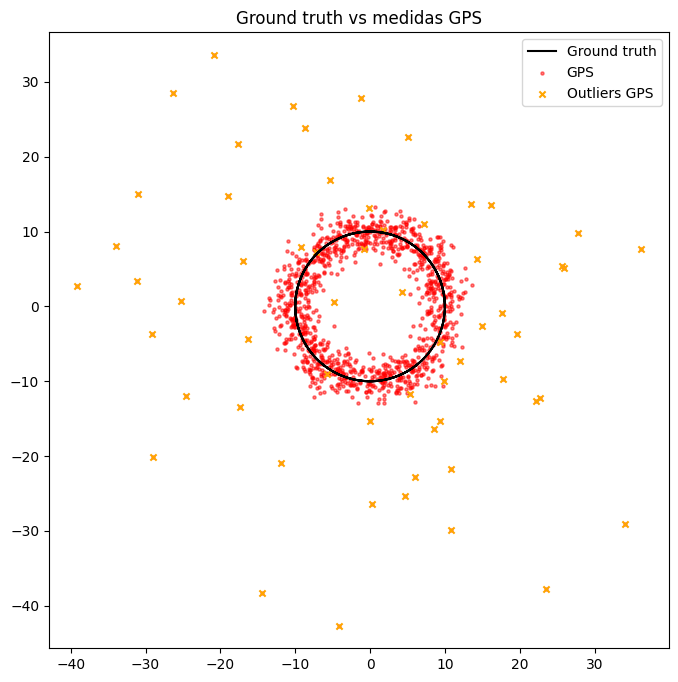

Medidas GPS descartadas por gating: 62 / 1200


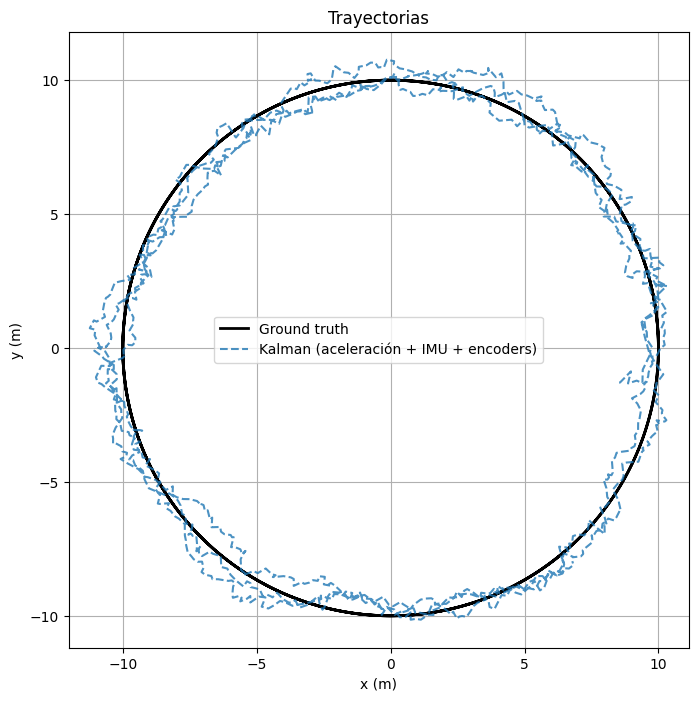

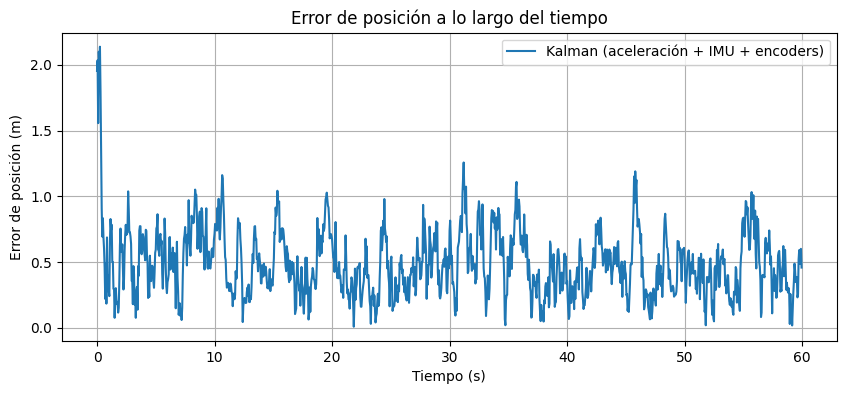

Kalman (aceleración + IMU + encoders)    RMSE=0.553 m  ATE=0.550 m  RPE=0.422 m


In [17]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman con GPS, IMU y encoders
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSIMUEncoders(
    dt=dt,
    sigma_gps=1.5,
    sigma_imu_a=0.1,
    sigma_imu_w=0.02,
    sigma_enc_v=0.05,
    sigma_enc_w=0.02
)

# Inicializar el estado con la primera medida GPS
kalman.x = np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # theta inicial
    0.0,   # v inicial
    0.0    # omega inicial
])

kalman.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])

estimates_kf = np.zeros((len(df_gt), 5))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medidas de la IMU
    a_imu = medidas['imu']['ax_imu'].iloc[i]
    omega_imu = medidas['imu']['omega_imu'].iloc[i]

    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])

    # Medidas de los encoders (convertidas a velocidad)
    v_enc = medidas['encoders']['ds_enc'].iloc[i] / dt
    omega_enc = medidas['encoders']['dtheta_enc'].iloc[i] / dt
    z_enc = (v_enc, omega_enc)

    # Paso del filtro: predicción + gating GPS + actualización encoders
    kalman.predict(a_imu, omega_imu)
    updated = kalman.update_gps_gating(z_gps, umbral=3.0)
    if not updated:
        n_descartadas += 1
    kalman.update_encoders(v_enc, omega_enc)

    estimates_kf[i] = kalman.x.copy()

print(f"Medidas GPS descartadas por gating: {n_descartadas} / {len(df_gt)}")

# 5. Representa el resultado
estimates = {'Kalman (aceleración + IMU + encoders)': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
# Nota: el ground truth solo tiene [x, y, vx, vy]; comparamos las dos primeras columnas.
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est[:, :4], gt_array, nombre)  # usamos [x, y, v, omega] → ajustar según métrica
    print(f"{m['name']:40s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al integrar medidas de otros sensores? ¿El error es adecuado o excesivo para la tarea? ¿Cómo crees que se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Comparamos el filtro de Kalman del ejercicio 2 con el GPS sin filtrar y con los Kalman del ejercicio 1, usando la misma trayectoria y las mismas medidas. Después miramos si el error es adecuado, qué aporta cada sensor y probamos algunos ajustes para intentar reducirlo más.

GPS sin filtrar                      RMSE=5.232 m  ATE=5.231 m  RPE=4.082 m
Kalman ej. 1 (GPS)                   RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m
Kalman ej. 1 con gating (GPS)        RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m
Kalman ej. 2 (GPS + IMU + encoders)  RMSE=0.553 m  ATE=0.550 m  RPE=0.422 m

El Kalman ej. 2 reduce el RMSE un 89 % respecto a: GPS sin filtrar
El Kalman ej. 2 reduce el RMSE un 65 % respecto a: Kalman ej. 1 (GPS)
El Kalman ej. 2 reduce el RMSE un 54 % respecto a: Kalman ej. 1 con gating (GPS)

Outliers rechazados: 56 de 59
Medidas buenas rechazadas: 6

Primer instante con error < 1 m: t = 0.40 s
Después del primer segundo: error medio = 0.48 m, 95 % del tiempo < 0.89 m, máximo = 1.26 m
Radio real: 9.98 m, radio estimado por Kalman ej. 1 con gating (GPS): 10.86 m
Radio real: 9.98 m, radio estimado por Kalman ej. 2 (GPS + IMU + encoders): 9.98 m

RMSE según los sensores usados:
  GPS + IMU + encoders                                   RMSE =  0.553 m   error a los

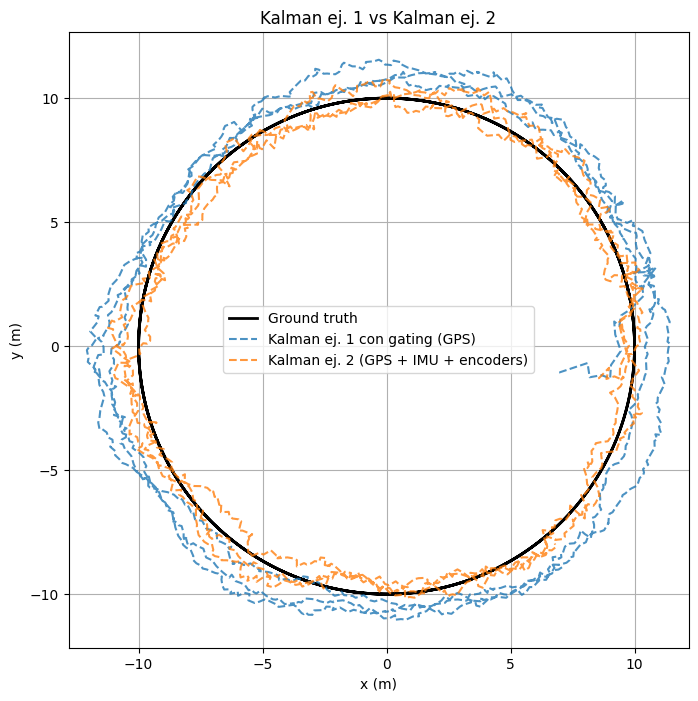

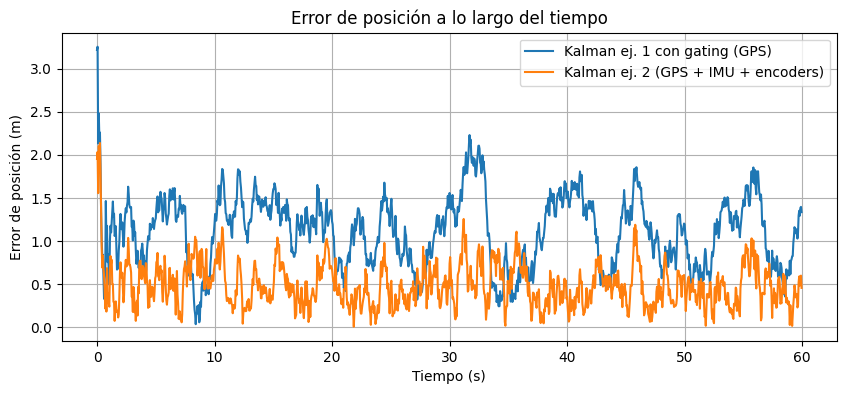

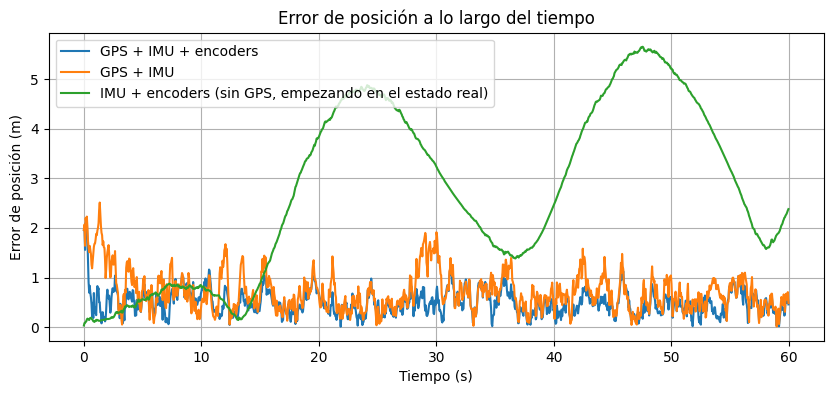

In [19]:
# Kalman ej. 2 (GPS + IMU + encoders) vs Kalman ej. 1 (solo GPS)

z_gps = medidas['gps'][['x_gps', 'y_gps']].values        # medidas del GPS
es_outlier = medidas['gps']['is_outlier'].values == 1     # True si la medida es un outlier
t = df_gt['t'].values


def ejecutar_ekf(usar_gps=True, usar_encoders=True, sigma_enc_v=0.05, sigma_enc_w=0.02, q_pos=0.01, x0=None):
    """Ejecuta el filtro de  Kalman del ejercicio 2 y devuelve las estimaciones
    y qué medidas del GPS se han rechazado. Los parámetros permiten quitar sensores o cambiar ajustes."""
    ekf = KalmanFilterGPSIMUEncoders(dt=dt, sigma_enc_v=sigma_enc_v, sigma_enc_w=sigma_enc_w)
    ekf.Q[0, 0] = ekf.Q[1, 1] = q_pos                       # ruido del proceso en la posición (en la clase 0.01)
    if x0 is None:
        x0 = np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0, 0.0])   
    ekf.x = x0.copy()
    ekf.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])
    est, rechazada = [], []
    for i in range(len(z_gps)):
        ekf.predict(medidas['imu']['ax_imu'].iloc[i], medidas['imu']['omega_imu'].iloc[i])
        rechazada.append(usar_gps and not ekf.update_gps_gating(z_gps[i], umbral=3.0))
        if usar_encoders:
            ekf.update_encoders(medidas['encoders']['ds_enc'].iloc[i] / dt,
                                medidas['encoders']['dtheta_enc'].iloc[i] / dt)
        est.append(ekf.x.copy())
    return np.array(est), np.array(rechazada)


# 1. Ejecutamos los filtros con las mismas medidas
kf1 = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
est_ej1 = np.array([kf1.step(z) for z in z_gps])
kf1_gating = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
est_ej1_gating = np.array([kf1_gating.step_gating(z) for z in z_gps])
est_ej2, rechazada = ejecutar_ekf()

# 2. Errores de cada uno
estimaciones = {
    'GPS sin filtrar':                     z_gps,
    'Kalman ej. 1 (GPS)':                  est_ej1,
    'Kalman ej. 1 con gating (GPS)':       est_ej1_gating,
    'Kalman ej. 2 (GPS + IMU + encoders)': est_ej2,
}
for nombre, est in estimaciones.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:36s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

# Cuánto baja el RMSE del Kalman del ejercicio 2 respecto a los demás
rmse_ej2 = rmse_posicion(est_ej2, gt_array)
print()
for nombre in ['GPS sin filtrar', 'Kalman ej. 1 (GPS)', 'Kalman ej. 1 con gating (GPS)']:
    reduccion = 100 * (1 - rmse_ej2 / rmse_posicion(estimaciones[nombre], gt_array))
    print(f"El Kalman ej. 2 reduce el RMSE un {reduccion:.0f} % respecto a: {nombre}")

# 3. Medidas rechazadas por el gating del Kalman del ejercicio 2
print(f"\nOutliers rechazados: {(rechazada & es_outlier).sum()} de {es_outlier.sum()}")
print(f"Medidas buenas rechazadas: {(rechazada & ~es_outlier).sum()}")

# 4. ¿Es adecuado el error? Error medio, percentil 95 y máximo, quitando el primer segundo (arranque)
error_ej2 = np.linalg.norm(est_ej2[:, :2] - gt_array[:, :2], axis=1)
print(f"\nPrimer instante con error < 1 m: t = {t[np.argmax(error_ej2 < 1.0)]:.2f} s")
tras_arranque = t > 1.0
print(f"Después del primer segundo: error medio = {error_ej2[tras_arranque].mean():.2f} m, "
      f"95 % del tiempo < {np.percentile(error_ej2[tras_arranque], 95):.2f} m, "
      f"máximo = {error_ej2[tras_arranque].max():.2f} m")

# 5. Radio del círculo real y del estimado 
centro = gt_array[:, :2].mean(axis=0)
radio_real = np.linalg.norm(gt_array[:, :2] - centro, axis=1).mean()
for nombre in ['Kalman ej. 1 con gating (GPS)', 'Kalman ej. 2 (GPS + IMU + encoders)']:
    radio = np.linalg.norm(estimaciones[nombre][:, :2] - centro, axis=1).mean()
    print(f"Radio real: {radio_real:.2f} m, radio estimado por {nombre}: {radio:.2f} m")

# 6. ¿Qué aporta cada sensor? Quitamos sensores uno a uno (la IMU siempre está, porque se usa en la predicción)
est_sin_enc, _ = ejecutar_ekf(usar_encoders=False)
# Sin GPS empezamos en el estado real, para que el error se deba solo a la deriva y no a un mal arranque
x0_real = np.array([gt_array[0, 0], gt_array[0, 1], np.arctan2(gt_array[0, 3], gt_array[0, 2]),
                    np.hypot(gt_array[0, 2], gt_array[0, 3]), df_gt['omega'].iloc[0]])
est_sin_gps, _ = ejecutar_ekf(usar_gps=False, x0=x0_real)
sensores = {
    'GPS + IMU + encoders': est_ej2,
    'GPS + IMU':            est_sin_enc,
    'IMU + encoders (sin GPS, empezando en el estado real)': est_sin_gps,
}
print("\nRMSE según los sensores usados:")
for nombre, est in sensores.items():
    error = np.linalg.norm(est[:, :2] - gt_array[:, :2], axis=1)
    print(f"  {nombre:54s} RMSE = {rmse_posicion(est, gt_array):6.3f} m   "
          f"error a los 10 s = {error[t <= 10][-1]:5.2f} m, al final = {error[-1]:5.2f} m")

# 7. Ideas para reducir el error
# a) Ruido de los encoders realista: en la clase σ_v = 0.05 m/s y σ_ω = 0.02 rad/s, pero en las medidas
#    el ruido real es mucho mayor
v_real = np.hypot(df_gt['vx'], df_gt['vy']).values
v_enc = medidas['encoders']['ds_enc'].values / dt
w_enc = medidas['encoders']['dtheta_enc'].values / dt
print(f"\nRuido real de los encoders: σ_v = {np.std(v_enc[1:] - v_real[1:]):.2f} m/s, "
      f"σ_ω = {np.std(w_enc[1:] - df_gt['omega'].values[1:]):.2f} rad/s")

# b) Ruido del proceso en la posición: probamos valores más pequeños que el de la clase (0.01)
print("\nRMSE según el ruido del proceso en la posición (q_pos):")
for q_pos in [0.01, 0.001, 0.0001]:
    est_q, _ = ejecutar_ekf(q_pos=q_pos)
    est_q_enc, _ = ejecutar_ekf(q_pos=q_pos, sigma_enc_v=0.4, sigma_enc_w=0.2)
    print(f"  q_pos = {q_pos}: RMSE = {rmse_posicion(est_q, gt_array):.3f} m, "
          f"con σ de encoders realistas = {rmse_posicion(est_q_enc, gt_array):.3f} m")

# c) Sesgo de la IMU: el giróscopo tiene un pequeño sesgo constante que el filtro no estima
print(f"\nSesgo medio del giróscopo: {(medidas['imu']['omega_imu'] - df_gt['omega']).mean():.4f} rad/s")

# Gráficas
comparacion = {
    'Kalman ej. 1 con gating (GPS)':       est_ej1_gating,
    'Kalman ej. 2 (GPS + IMU + encoders)': est_ej2,
}
plot_path(df_gt, comparacion, title='Kalman ej. 1 vs Kalman ej. 2')
plot_error(df_gt, comparacion)
plot_error(df_gt, sensores)

### Respuestas

**¿Cuánto ha decrecido el error al integrar medidas de otros sensores?**

Vemos que al incluir más sensores, el RMSE se reduce un 89 % respecto a GPS sin filtrar, un 65 % respecto a al filtro de Kalman del ej. 1 (GPS) y un 54 % respecto al filtro de Kalman del ej. 1 con gating (GPS).

La mayor parte de la mejora viene de que el modelo ahora incluye el giro. En el ejercicio 1 el círculo estimado tenía un radio de 10.86 m frente a 9.98 m reales, porque el filtro suponía que el robot iba recto. Con la IMU, el filtro sabe que el robot está girando y el radio estimado es de 9.98 m, igual que el real. En cambio, el RPE apenas cambia (0.43 m frente a 0.42 m): el movimiento a corto plazo ya se seguía bien, y lo que se ha corregido es el error que se iba acumulando en las curvas.

El gating también funciona mejor: rechaza 56 de los 59 outliers y solo 6 medidas buenas, frente a las 28 del ejercicio 1. Como la predicción es más precisa, las medidas buenas ya no parecen sospechosas.

Al quitar sensores se ve qué aporta cada uno. Sin encoders, el RMSE sube a 0.81 m. Sin GPS, aunque el filtro empiece en el estado exacto, el error crece sin parar hasta 2.38 m al final, porque la IMU y los encoders solo miden cambios y sus errores se van sumando. El GPS es la única referencia absoluta, y es lo que impide que el error se acumule.

**¿El error es adecuado o excesivo para la tarea?**

En este caso, como la tarea es solo localizar al robot, creemos que el error es adecuado, pero si fuese una tarea que requiere más precisión, como aparcar o pasar por una puerta estrecha si sería alto. Tras el arranque (el filtro baja de 1 m de error en 0.4 s), el error medio es de 0.48 m, el 95 % del tiempo está por debajo de 0.89 m y el máximo es 1.26 m. 

**¿Cómo crees que se podría seguir reduciendo?**

- **Ajustar cuánto se fía el filtro de su predicción (Q).** Con el valor de la clase, el filtro sigue demasiado al GPS y copia su ruido. Bajando el ruido de posición de 0.01 a 0.001, el RMSE pasa de 0.55 m a 0.51 m (un 8 % menos). Si se baja más, empeora, porque el filtro empieza a ignorar el GPS.
- **Usar el ruido real de los encoders.** La clase supone que son más precisos de lo que son en realidad. Corregirlo casi no cambia el RMSE, pero hace que el filtro no se fíe de más de un sensor ruidoso.
- **Estimar el sesgo del giróscopo.** La IMU marca siempre un poco más de giro del real (unos 0.01 rad/s). Si se añade al estado, el filtro puede aprenderlo y corregirlo.
- **Mejorar el GPS.** Es el sensor que limita el error que queda, así que uno más preciso o con más medidas por segundo lo reduciría.


### Ejercicio 3: Filtro de Partículas

Implementar un filtro de Partículas para fusionar las medidas del GPS, la IMU y los encoders, obteniendo una localización precisa del robot. 

1. Crea la función de inicialización, que distribuye las partículas alrededor del estado inicial
2. Crea la función de predicción, que propaga las partículas según el modelo y añadiendo ruido
3. Crea la función de actualización, que actualiza los pesos según la verosimilitud de la medida del GPS
4. Crea la función de remuestreo, que filtra las partículas según sus pesos.

In [20]:
class ParticleFilter:
    """
    Filtro de partículas para fusión de GPS + IMU + encoders
    Estado: [x, y, vx, vy]
    """
    def __init__(self, dt, n_particulas=500, sigma_gps=1.5):
        self.dt = dt
        self.N = n_particulas
        self.sigma_gps = sigma_gps
        self.rng = np.random.default_rng(0)
        
        self.particulas = np.zeros((self.N, 4))
        self.pesos = np.ones(self.N) / self.N
    
    def initialize(self, x0):
        """Inicializa partículas alrededor de x0"""
        self.particulas = x0 + self.rng.normal(0, self.sigma_gps, size=(self.N, 4))
    
    def predict(self, a_imu=None, omega_imu=None):
        """Propaga partículas con el modelo de movimiento + ruido"""
        x, y, vx, vy = self.particulas.T

        # Actualizamos la velocidad con la aceleración de la IMU
        if a_imu is not None:
            vx += a_imu[0] * self.dt
            vy += a_imu[1] * self.dt

        # Actualizamos la posición con la velocidad
        x += vx * self.dt
        y += vy * self.dt

        # Añadimos ruido de proceso cogiendo unos valores arbitrarios
        x += self.rng.normal(0, 0.1, size=self.N)
        y += self.rng.normal(0, 0.1, size=self.N)
        vx += self.rng.normal(0, 0.05, size=self.N)
        vy += self.rng.normal(0, 0.05, size=self.N)
        self.particulas = np.vstack((x, y, vx, vy)).T       
    
    def update(self, z_gps):
        """Actualiza pesos según verosimilitud de la medida GPS"""
        z_gps = np.asarray(z_gps)

        # Calculamos la distancia euclídea entre cada partícula y la medida GPS
        distancias = np.linalg.norm(self.particulas[:, :2] - z_gps[:2], axis=1)

        # Calculamos la verosimilitud usando una distribución normal
        self.pesos = np.exp(-0.5 * (distancias / self.sigma_gps)**2)
        self.pesos += 1e-300  # Evitamos pesos nulos
        self.pesos /= np.sum(self.pesos)  # Normalizamos los pesos
    
    def resampling(self):
        """Resampling sistemático"""
        indices = np.zeros(self.N, dtype=int)
        cumsum = np.cumsum(self.pesos)
        step = 1.0 / self.N
        u0 = self.rng.uniform(0, step)
        j = 0
        for i in range(self.N):
            u = u0 + i * step
            while u > cumsum[j]:
                j += 1
            indices[i] = j
        self.particulas = self.particulas[indices]
        self.pesos.fill(1.0 / self.N)
    
    def estimate(self):
        """Devuelve la media ponderada de las partículas"""
        return np.average(self.particulas, axis=0, weights=self.pesos)
    
    def step(self, z_gps, a_imu=None):
        self.predict(a_imu)
        if z_gps is not None:
            self.update(z_gps)
            self.resampling()
        return self.estimate()

    def step_with_gating(self, z_gps, a_imu=None, umbral=5.0):
        self.predict(a_imu)
        if z_gps is not None:
            # Gating euclídeo: descartar si la medida está muy lejos de la estimación
            estimacion = self.estimate()
            distancia = np.linalg.norm(z_gps[:2] - estimacion[:2])
            if distancia < umbral:
                self.update(z_gps)
                self.resampling()
        return self.estimate()

B) Analiza el rendimiento del filtro de partículas con y sin gating.

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


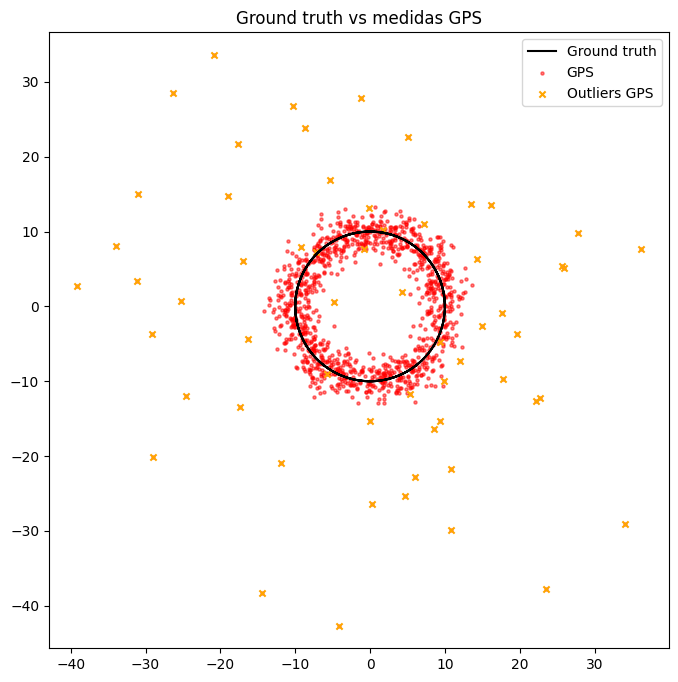

Muestras procesadas: 1200
Muestras procesadas: 1200


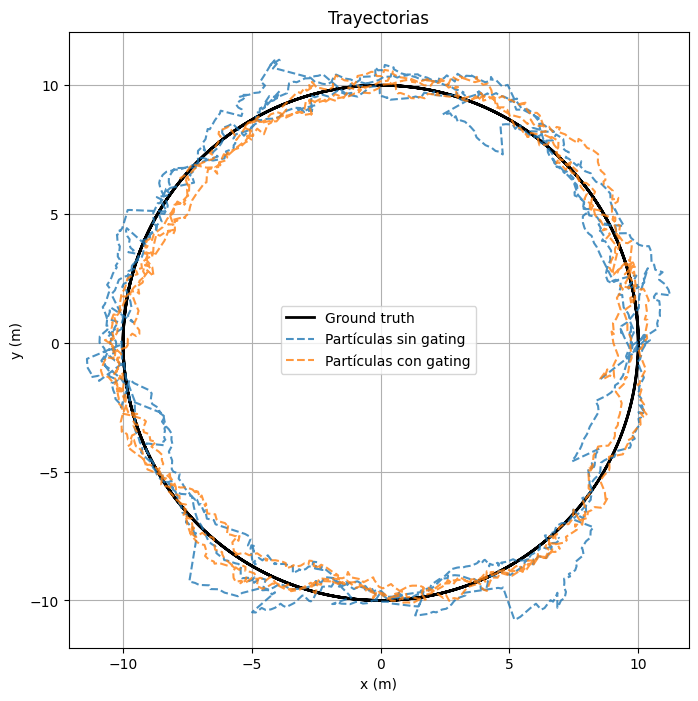

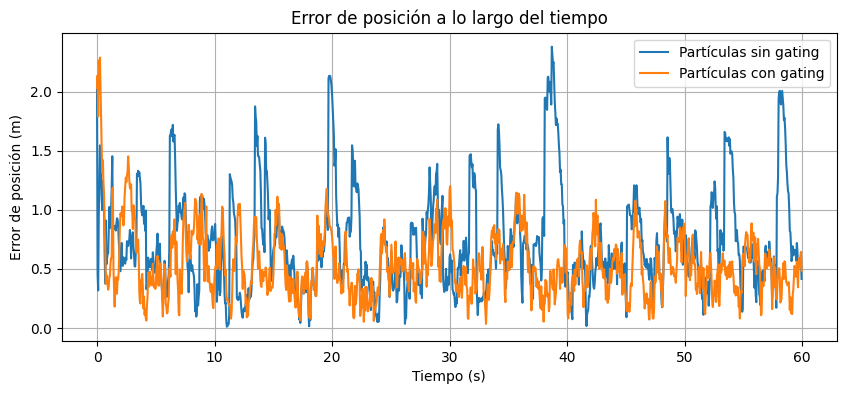

Partículas sin gating          RMSE=0.846 m  ATE=0.844 m  RPE=0.665 m
Partículas con gating          RMSE=0.604 m  ATE=0.596 m  RPE=0.436 m


In [21]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de partículas sin gating
dt = 1.0 / meta['frecuencia_hz']

pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf = np.zeros((len(df_gt), 4))

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])
    a_imu = np.array([medidas['imu']['ax_imu'].iloc[i], medidas['imu']['ay_imu'].iloc[i]])

    # Paso del filtro de partículas
    estimates_pf[i] = pf.step(z_gps, a_imu)

print(f"Muestras procesadas: {len(df_gt)}")

# 5. Ejecuta el filtro de partículas con gating
pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf_gating = np.zeros((len(df_gt), 4))

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])
    a_imu = np.array([medidas['imu']['ax_imu'].iloc[i], medidas['imu']['ay_imu'].iloc[i]])

    # Paso del filtro de partículas
    estimates_pf_gating[i] = pf.step_with_gating(z_gps, a_imu)

print(f"Muestras procesadas: {len(df_gt)}")

# 6. Representa el resultado
estimates = {'Partículas sin gating': estimates_pf, 'Partículas con gating': estimates_pf_gating}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 7. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:30s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza los resultados del filtro de partículas. ¿El gating es interesante? ¿Cuál es su rendimiento en comparación con el filtro de Kalman? ¿Por qué crees que ocurre esto?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Miramos qué medidas rechaza el gating, probamos el filtro sin la IMU y lo comparamos con los filtros de Kalman de los ejercicios anteriores.

Outliers rechazados: 56 de 59
Medidas buenas rechazadas: 2

Kalman ej. 1 (GPS)                   RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m
Kalman ej. 1 con gating (GPS)        RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m
Kalman ej. 2 (GPS + IMU + encoders)  RMSE=0.553 m  ATE=0.550 m  RPE=0.422 m
Partículas sin IMU                   RMSE=8.393 m  ATE=6.294 m  RPE=0.946 m
Partículas sin IMU con gating        RMSE=128.204 m  ATE=66.151 m  RPE=2.225 m
Partículas (GPS + IMU)               RMSE=0.846 m  ATE=0.844 m  RPE=0.665 m
Partículas con gating (GPS + IMU)    RMSE=0.604 m  ATE=0.596 m  RPE=0.436 m


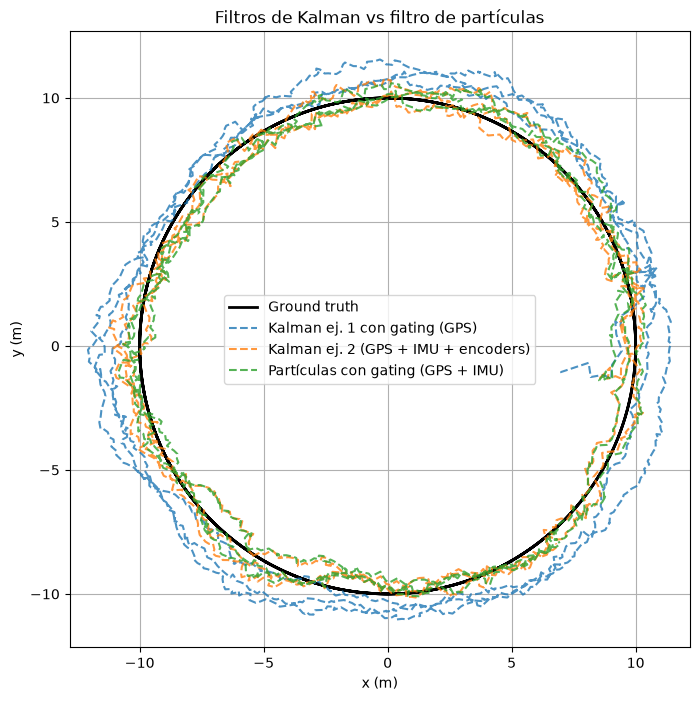

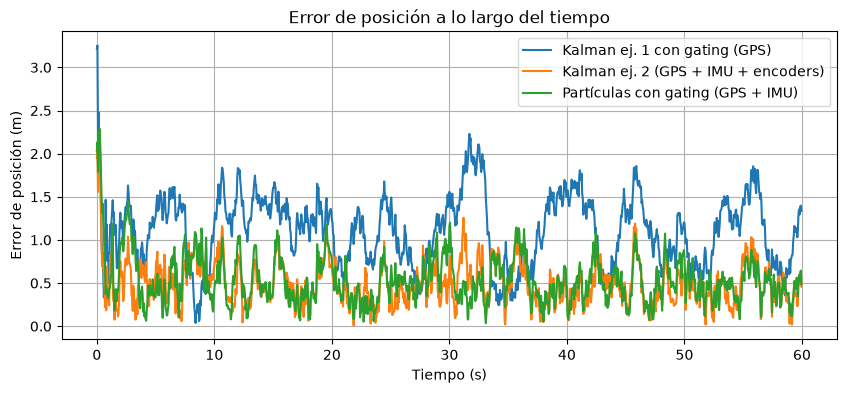

In [ ]:
#Filtro de partículas: gating y comparación con los filtros de Kalman 
# Usamos resultados de celdas anteriores (misma trayectoria y mismas medidas):
#   est_sin, est_con                   -> Kalman del ejercicio 1 (apartado D)
#   estimates_kf                       -> Kalman del ejercicio 2
#   estimates_pf, estimates_pf_gating  -> filtro de partículas (celda anterior)

z_gps = medidas['gps'][['x_gps', 'y_gps']].values       # medidas del GPS
es_outlier = medidas['gps']['is_outlier'].values == 1    # True si la medida es un outlier
a_imu = medidas['imu'][['ax_imu', 'ay_imu']].values      # aceleraciones de la IMU
x0 = np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0])      # primera medida GPS y velocidad 0

# 1. ¿Qué medidas rechaza el gating? (mismos pasos que step_with_gating)
pf = ParticleFilter(dt=dt)
pf.initialize(x0)
rechazada = []
for i in range(len(z_gps)):
    pf.predict(a_imu[i])
    distancia = np.linalg.norm(z_gps[i] - pf.estimate()[:2])
    if distancia < 5.0:
        pf.update(z_gps[i])
        pf.resampling()
    rechazada.append(distancia >= 5.0)
rechazada = np.array(rechazada)
print(f"Outliers rechazados: {(rechazada & es_outlier).sum()} de {es_outlier.sum()}")
print(f"Medidas buenas rechazadas: {(rechazada & ~es_outlier).sum()}")

# 2. Filtro de partículas sin pasarle la IMU
pf_sin_imu = ParticleFilter(dt=dt)
pf_sin_imu.initialize(x0)
est_pf_sin_imu = np.array([pf_sin_imu.step(z) for z in z_gps])

pf_sin_imu_gating = ParticleFilter(dt=dt)
pf_sin_imu_gating.initialize(x0)
est_pf_sin_imu_gating = np.array([pf_sin_imu_gating.step_with_gating(z) for z in z_gps])

# 3. Comparación de todos los filtros
todos = {
    'Kalman ej. 1 (GPS)':                  est_sin,
    'Kalman ej. 1 con gating (GPS)':       est_con,
    'Kalman ej. 2 (GPS + IMU + encoders)': estimates_kf,
    'Partículas sin IMU':                  est_pf_sin_imu,
    'Partículas sin IMU con gating':       est_pf_sin_imu_gating,
    'Partículas (GPS + IMU)':              estimates_pf,
    'Partículas con gating (GPS + IMU)':   estimates_pf_gating,
}
print()
for nombre, est in todos.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:36s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

# 4. Gráficas de los tres mejores
mejores = {
    'Kalman ej. 1 con gating (GPS)':       est_con,
    'Kalman ej. 2 (GPS + IMU + encoders)': estimates_kf,
    'Partículas con gating (GPS + IMU)':   estimates_pf_gating,
}
plot_path(df_gt, mejores, title='Filtros de Kalman vs filtro de partículas')
plot_error(df_gt, mejores)

#### Respuestas

**¿El gating es interesante?**

Sí. Con gating el RMSE baja de 0.85 m a 0.60 m. Rechaza 56 de los 59 outliers y solo 2 medidas buenas. Sin gating, cuando llega un outlier las partículas que están cerca de él ganan peso, se copian en el remuestreo y la estimación se va hacia donde no está el robot.

Pero también vimos que puede ser peligroso. Al principio no le pasábamos la IMU al filtro y no conseguía seguir la curva (RMSE de 8.39 m). Con gating fue mucho peor, 128 m: en cuanto la estimación se alejaba más de 5 m del robot, todas las medidas del GPS le parecían outliers, las rechazaba todas y ya no volvía. Así que el gating solo ayuda si el filtro ya está siguiendo bien al robot.

**¿Cuál es su rendimiento en comparación con el filtro de Kalman?**

| Filtro | Sensores | RMSE |
|---|---|---|
| Kalman ej. 1 | GPS | 1.58 m |
| Kalman ej. 1 con gating | GPS | 1.19 m |
| Partículas | GPS + IMU | 0.85 m |
| Partículas con gating | GPS + IMU | 0.60 m |
| Kalman ej. 2 | GPS + IMU + encoders | 0.55 m |

El filtro de partículas es bastante mejor que el Kalman del ejercicio 1 y se acerca al del ejercicio 2, aunque este sigue siendo un poco mejor.

**¿Por qué crees que ocurre esto?**

Frente al Kalman del ejercicio 1, creemos que la diferencia viene sobre todo de la IMU y no del tipo de filtro, porque el filtro de partículas sin IMU es mucho peor que ese Kalman. Con la aceleración, las partículas pueden seguir la curva, que era justo el problema del ejercicio 1.

Frente al Kalman del ejercicio 2, ese filtro usa además los encoders, así que tiene más información. Además, según la tabla de conclusiones del tema, el Kalman es óptimo cuando el ruido es gaussiano y el modelo es lineal, y en esta práctica el ruido del GPS es gaussiano, así que la ventaja del filtro de partículas aquí no se nota. Encima el filtro de partículas es más lento (500 partículas en cada paso) y depende de valores que hemos elegido a mano, como el ruido que se añade a las partículas.

Para este problema nos quedaríamos con el Kalman del ejercicio 2.

### Prueba con otras trayectorias

En el ejercicio 1 concluimos que gran parte del error del Kalman viene de que el modelo supone que el robot va recto, mientras que en el círculo está girando todo el rato, como solo habíamos usado la trayectoria circular queríamos comprobar cómo funciona con otras. Para comprobarlo, probamos los filtros en el resto de trayectorias y en una nueva que hemos creado en `path_generator.ipynb`: una **línea recta** en diagonal a 3 m/s. Es la misma velocidad que en el círculo, así que lo único que cambia es que no hay giros.

**Hipótesis:**

1. **Línea recta:** el modelo de velocidad constante describe justo lo que hace el robot, así que el Kalman del ejercicio 1 debería funcionar mucho mejor que en el círculo y acercarse a los filtros que usan más sensores.
2. **Ocho:** tiene las curvas más cerradas y además cambia el sentido de giro, así que debería ser el peor caso para el Kalman del ejercicio 1.
3. **Cuadrada y urbana:** mezclan tramos rectos y giros, así que esperamos resultados intermedios.
4. **Kalman del ejercicio 2 y filtro de partículas:** como usan la IMU (y el Kalman también los encoders), deberían depender mucho menos de la forma de la trayectoria.

recta     Kalman ej. 2           primeros 10 s = 0.62 m, resto = 0.49 m
recta     Partículas con gating  primeros 10 s = 0.69 m, resto = 0.50 m
circular  Kalman ej. 2           primeros 10 s = 0.59 m, resto = 0.47 m
circular  Partículas con gating  primeros 10 s = 0.68 m, resto = 0.50 m
cuadrada  Kalman ej. 2           primeros 10 s = 0.56 m, resto = 0.44 m
cuadrada  Partículas con gating  primeros 10 s = 0.66 m, resto = 0.50 m
urbana    Kalman ej. 2           primeros 10 s = 0.57 m, resto = 0.48 m
urbana    Partículas con gating  primeros 10 s = 1.38 m, resto = 0.50 m
ocho      Kalman ej. 2           primeros 10 s = 0.61 m, resto = 0.51 m
ocho      Partículas con gating  primeros 10 s = 2.32 m, resto = 0.49 m


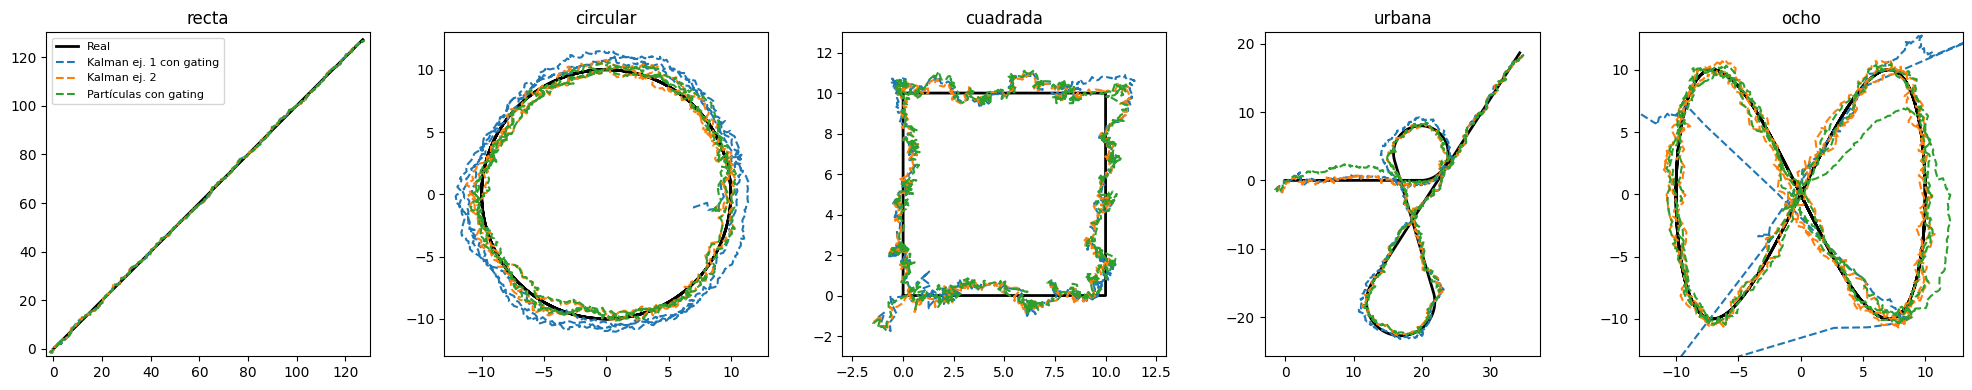

,Trayectoria,Velocidad media (m/s),Giro medio |ω| (rad/s),Kalman ej. 1,Kalman ej. 1 con gating,Kalman ej. 2,Partículas con gating
0,recta,3.00,0.00,1.17,0.61,0.58,0.59
1,circular,3.00,0.30,1.58,1.19,0.55,0.60
2,cuadrada,0.67,0.13,1.16,0.62,0.52,0.59
3,urbana,2.00,0.15,1.29,0.75,0.56,0.80
4,ocho,4.50,1.10,2.68,40.46,0.61,1.19


In [22]:
# Probamos los filtros en todas las trayectorias

def probar_filtros(nombre):
    """Ejecuta los filtros principales en una trayectoria y devuelve el RMSE de cada uno y sus estimaciones."""
    df, meta = load_path(nombre)
    medidas = SensorSimulator(seed=42).sim_sensors(df)
    dt = 1.0 / meta['frecuencia_hz']
    gt = df[['x', 'y', 'vx', 'vy']].values
    z_gps = medidas['gps'][['x_gps', 'y_gps']].values
    a_imu = medidas['imu'][['ax_imu', 'ay_imu']].values

    # Kalman del ejercicio 1, sin y con gating
    kf = KalmanFilterGPS(dt=dt)
    est_kf = np.array([kf.step(z) for z in z_gps])
    kf_gating = KalmanFilterGPSwithGating(dt=dt)
    est_kf_gating = np.array([kf_gating.step_gating(z) for z in z_gps])

    # Kalman del ejercicio 2 (igual que en la celda del apartado 2B)
    ekf = KalmanFilterGPSIMUEncoders(dt=dt)
    ekf.x = np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0, 0.0])
    ekf.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])
    est_ekf = []
    for i in range(len(z_gps)):
        ekf.predict(medidas['imu']['ax_imu'].iloc[i], medidas['imu']['omega_imu'].iloc[i])
        ekf.update_gps_gating(z_gps[i], umbral=3.0)
        ekf.update_encoders(medidas['encoders']['ds_enc'].iloc[i] / dt,
                            medidas['encoders']['dtheta_enc'].iloc[i] / dt)
        est_ekf.append(ekf.x.copy())
    est_ekf = np.array(est_ekf)

    # Filtro de partículas con gating
    pf = ParticleFilter(dt=dt)
    pf.initialize(np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0]))
    est_pf = np.array([pf.step_with_gating(z_gps[i], a_imu[i]) for i in range(len(z_gps))])

    fila = {
        'Trayectoria': nombre.replace('trayectoria_', ''),
        'Velocidad media (m/s)': np.hypot(df['vx'], df['vy']).mean(),
        'Giro medio |ω| (rad/s)': np.abs(df['omega']).mean(),
        'Kalman ej. 1': rmse_posicion(est_kf, gt),
        'Kalman ej. 1 con gating': rmse_posicion(est_kf_gating, gt),
        'Kalman ej. 2': rmse_posicion(est_ekf, gt),
        'Partículas con gating': rmse_posicion(est_pf, gt),
    }
    estimaciones = {'Kalman ej. 1 con gating': est_kf_gating, 'Kalman ej. 2': est_ekf,
                    'Partículas con gating': est_pf}
    return fila, df, estimaciones

nombres = ['trayectoria_recta', 'trayectoria_circular', 'trayectoria_cuadrada',
           'trayectoria_urbana', 'trayectoria_ocho']

# Un gráfico pequeño por trayectoria con la trayectoria real y la de cada filtro
filas = []
fig, axes = plt.subplots(1, len(nombres), figsize=(20, 4))
for ax, nombre in zip(axes, nombres):
    fila, df, estimaciones = probar_filtros(nombre)
    filas.append(fila)

    # Error medio en los primeros 10 s (200 muestras) y en el resto del recorrido
    for etiqueta in ['Kalman ej. 2', 'Partículas con gating']:
        error = np.linalg.norm(estimaciones[etiqueta][:, :2] - df[['x', 'y']].values, axis=1)
        print(f"{fila['Trayectoria']:9s} {etiqueta:22s} primeros 10 s = {error[:200].mean():.2f} m, resto = {error[200:].mean():.2f} m")

    ax.plot(df['x'], df['y'], 'k-', lw=2, label='Real')
    for etiqueta, est in estimaciones.items():
        ax.plot(est[:, 0], est[:, 1], '--', label=etiqueta)
    # Fijamos los ejes a la trayectoria real para que un filtro que se pierde no deforme el gráfico
    ax.set_xlim(df['x'].min() - 3, df['x'].max() + 3)
    ax.set_ylim(df['y'].min() - 3, df['y'].max() + 3)
    ax.set_aspect('equal')
    ax.set_title(fila['Trayectoria'])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

tabla = pd.DataFrame(filas)
tabla.round(2)

#### Resultados

**¿Se cumplen las hipótesis?**

1. **Línea recta: sí.** El Kalman del ejercicio 1 con gating baja de 1.19 m en el círculo a 0.61 m en la recta, casi igual que el Kalman del ejercicio 2 (0.58 m). Como la velocidad es la misma en las dos trayectorias, la diferencia solo puede venir de los giros, así que esto confirma lo que pensábamos en el ejercicio 1. Sin gating se queda en 1.17 m: en la recta, el error que queda viene de los outliers. En el gráfico de la recta no se aprecia la diferencia entre filtros porque la recta mide más de 120 m y con esa escala no se ven errores de medio metro, así que aquí nos fijamos en la tabla.
2. **Ocho: sí.** Sin gating, el Kalman del ejercicio 1 da el peor resultado de todas las trayectorias (2.68 m). Pero con gating el error se va a 40 m. Nos pasa lo mismo que con el filtro de partículas sin IMU: el robot va rápido (4.5 m/s de media) y gira mucho, así que la predicción en línea recta se aleja del robot en pocos segundos. A partir de ahí el gating cree que las medidas buenas son outliers y las rechaza (descarta 1008 de las 1141 medidas buenas), así que el filtro ya no se recupera. En el gráfico del ocho se ve el momento en que pasa: la línea del Kalman del ejercicio 1 se sale en línea recta y ya no vuelve. No esperábamos que el gating pudiera empeorar tanto también al Kalman.
3. **Cuadrada y urbana: más o menos.** Quedan entre la recta y el círculo, como esperábamos. La cuadrada sale casi igual que la recta, pero creemos que es sobre todo porque el robot va muy despacio (0.67 m/s), así que en los giros le da tiempo a corregirse. Aun así, en el gráfico se ve que en las esquinas todos los filtros se pasan un poco: siguen rectos unos instantes antes de girar. Es el mismo problema que en el círculo, pero concentrado en giros bruscos de 90°.
4. **Kalman del ejercicio 2: sí.** Está entre 0.52 y 0.61 m en todas las trayectorias, incluido el ocho. El **filtro de partículas** aguanta mucho mejor que el Kalman del ejercicio 1, pero empeora en el ocho (1.19 m) y en la urbana (0.80 m). Al principio pensábamos que era porque no usa los encoders, pero en el gráfico de la urbana vimos que la línea de las partículas se separaba sobre todo al principio. Midiendo el error por separado, en los primeros 10 s es de 1.38 m en la urbana y de 2.32 m en el ocho, y en el resto del recorrido baja a 0.50 m, prácticamente igual que el Kalman del ejercicio 2. Así que el problema parece estar en el arranque, y lo comprobamos en la celda siguiente.

In [23]:
# Comprobación: arranque del filtro de partículas 
# Repetimos el filtro de partículas con distintas semillas aleatorias,
# empezando con velocidad 0 (como hasta ahora) y con la velocidad inicial real del robot

for nombre in ['trayectoria_urbana', 'trayectoria_ocho']:
    df, meta = load_path(nombre)
    medidas_tray = SensorSimulator(seed=42).sim_sensors(df)
    z_tray = medidas_tray['gps'][['x_gps', 'y_gps']].values
    a_tray = medidas_tray['imu'][['ax_imu', 'ay_imu']].values
    gt_tray = df[['x', 'y', 'vx', 'vy']].values
    v_real = df[['vx', 'vy']].values[0]
    print(f"{nombre} (velocidad inicial real = {np.hypot(v_real[0], v_real[1]):.1f} m/s)")

    for semilla in [0, 1, 2]:
        for texto, v0 in [('velocidad inicial 0   ', [0.0, 0.0]), ('velocidad inicial real', v_real)]:
            pf = ParticleFilter(dt=dt)
            pf.rng = np.random.default_rng(semilla)
            pf.initialize(np.array([z_tray[0, 0], z_tray[0, 1], v0[0], v0[1]]))
            est = np.array([pf.step_with_gating(z_tray[i], a_tray[i]) for i in range(len(z_tray))])
            print(f"  semilla {semilla}, {texto}: RMSE = {rmse_posicion(est, gt_tray):.2f} m")

trayectoria_urbana (velocidad inicial real = 2.0 m/s)
  semilla 0, velocidad inicial 0   : RMSE = 0.80 m
  semilla 0, velocidad inicial real: RMSE = 0.58 m
  semilla 1, velocidad inicial 0   : RMSE = 0.58 m
  semilla 1, velocidad inicial real: RMSE = 0.58 m
  semilla 2, velocidad inicial 0   : RMSE = 0.58 m
  semilla 2, velocidad inicial real: RMSE = 0.58 m
trayectoria_ocho (velocidad inicial real = 6.7 m/s)
  semilla 0, velocidad inicial 0   : RMSE = 1.19 m
  semilla 0, velocidad inicial real: RMSE = 0.58 m
  semilla 1, velocidad inicial 0   : RMSE = 134.16 m
  semilla 1, velocidad inicial real: RMSE = 0.57 m
  semilla 2, velocidad inicial 0   : RMSE = 84.67 m
  semilla 2, velocidad inicial real: RMSE = 0.57 m


#### Arranque del filtro de partículas

Las partículas empiezan con velocidad 0 y la IMU solo les dice cómo cambia la velocidad, no cuál es, así que al principio tienen que encontrarla. En la prueba anterior vemos que:

- Si empiezan con la velocidad real, el RMSE es de unos 0.58 m en las dos trayectorias y con todas las semillas, igual que el Kalman del ejercicio 2.
- En la urbana el mal arranque fue en parte mala suerte: con la semilla 0 sale 0.80 m, pero con las otras dos sale 0.58 m.
- En el ocho es mucho más grave: el robot empieza a 6.7 m/s y, según la semilla, el filtro se pierde del todo (134 m y 85 m) y el gating ya no le deja recuperarse. Con la semilla 0, que es la que usábamos, tuvimos suerte.

De aquí sacamos dos cosas. Primero, que el filtro de partículas depende mucho de la inicialización y del azar, así que con una sola ejecución no basta para sacar conclusiones. Segundo, que el Kalman del ejercicio 2 no tiene este problema porque los encoders le dan la velocidad desde el principio. En un robot real se podría inicializar la velocidad de las partículas con la de los encoders, o al menos darles más dispersión en la velocidad inicial.